<a href="https://colab.research.google.com/github/RebeccaDai615/Social_Media_Data_Segmentation/blob/main/Social_Media_Data_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## References

[Pandas](https://pandas.pydata.org/docs/)

[Matplotlib](https://matplotlib.org/)

[Plotly](https://plotly.com/)

[NLTK](https://www.nltk.org/)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Input Data

1. Download the data from Octoparse
2. Upload the file at `My Drive/MUDP2020_Social Media` and rename it as `Restaurant_Listings.xlsx` and `Restaurant_Reviews.xlsx`

### *Importing the libraries that are used*

In [ ]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import nltk
nltk.download('vader_lexicon')
from nltk.sentiment import SentimentIntensityAnalyzer
import folium
from folium.plugins import HeatMap
import torch
from transformers import BertTokenizer, BertForSequenceClassification, AutoModelForSequenceClassification, AutoTokenizer
import numpy as np

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


###Mount Google Drive to access the social media data

In [ ]:
from google.colab import drive
try:
  drive.mount('/content/drive', force_remount = True)
except:
  drive._mount('/content/drive', force_remount = True)

Mounted at /content/drive


# The following codeblocks might need your inputs

In [ ]:
import pandas as pd
from google.colab import drive

# 挂载 Drive
drive.mount('/content/drive')

# 直接粘贴你的文件完整路径（右键文件 → 复制路径）
file_path = '/content/drive/MyDrive/4.14cleanedresults/4.14最终调整版revisedcleanedresults.csv'  # 在两个引号之间粘贴路径

# 读取文件
df_review = pd.read_csv(file_path)

print("✅ 读取成功")
print(df_review.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ 读取成功
                                        Original_URL               Name  \
0  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   
1  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   
2  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   
3  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   
4  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   

  Review_Date                            Review   Latitude   Longitude  
0         NaN              DX Design Hub 香港設計中心  22.329075  114.159381  
1         NaN           Wai Kuen Chak (Raymond)  22.329075  114.159381  
2         NaN  Tsang Chiu WAH23@gmail.com Tsang  22.329075  114.159381  
3         NaN         Terry “Monochromist” Chua  22.329075  114.159381  
4         NaN    Búñgá Núsá Iñdáh FORSA (BUNGA) 

In [ ]:
import pandas as pd
from google.colab import drive

# 挂载 Drive
drive.mount('/content/drive')

# 直接粘贴你的地点列表文件的完整路径
listing_path = '/content/drive/MyDrive/4.14cleanedresults/4.14最终调整版revisedcleanedresults.csv'  # 在两个引号之间粘贴路径

# 读取文件（如果是 CSV 用 read_csv，如果是 Excel 用 read_excel）
df_listing = pd.read_csv(listing_path)  # 如果是 .csv
# df_listing = pd.read_excel(listing_path)  # 如果是 .xlsx 或 .xls

print("✅ 地点列表加载成功")
print(df_listing.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ 地点列表加载成功
                                        Original_URL               Name  \
0  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   
1  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   
2  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   
3  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   
4  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   

  Review_Date                            Review   Latitude   Longitude  
0         NaN              DX Design Hub 香港設計中心  22.329075  114.159381  
1         NaN           Wai Kuen Chak (Raymond)  22.329075  114.159381  
2         NaN  Tsang Chiu WAH23@gmail.com Tsang  22.329075  114.159381  
3         NaN         Terry “Monochromist” Chua  22.329075  114.159381  
4         NaN    Búñgá Núsá Iñdáh FORSA (BUN

#Data Preprocessing

In [ ]:
def parse_review_date(review_date):
  if 'year' in review_date:
    years_ago = 1
    if 'years' in review_date:
      years_ago = int(review_date.split()[0])
    return (datetime.now() - timedelta(days=years_ago * 365)).date()
  elif 'month' in review_date:
    months_ago = 1
    if 'months' in review_date:
      months_ago = int(review_date.split()[0])
    return (datetime.now() - timedelta(days=months_ago * 30)).date()
  elif 'week' in review_date:
    weeks_ago = 1
    if 'weeks' in review_date:
      weeks_ago = int(review_date.split()[0])
    return (datetime.now() - timedelta(weeks=weeks_ago)).date()
  elif 'day' in review_date:
    days_ago = 1
    if 'days' in review_date:
      days_ago = int(review_date.split()[0])
    return (datetime.now() - timedelta(days=days_ago)).date()
  elif 'hour' in review_date:
    hours_ago = 1
    if 'hours' in review_date:
      hours_ago = int(review_date.split()[0])
    return (datetime.now() - timedelta(hours=hours_ago)).date()
  else:
    return (datetime.now()).date()

In [ ]:
import pandas as pd
from google.colab import drive

# 1. 挂载 Google Drive
drive.mount('/content/drive')

# 2. 【关键】直接粘贴你评论文件的完整路径
# 在 Colab 左侧文件管理器找到文件 -> 右键 -> 复制路径 -> 粘贴到下面的引号里
review_path = '/content/drive/MyDrive/4.14cleanedresults/4.14最终调整版revisedcleanedresults.csv'  # 👈 把路径粘贴在这里

# 3. 读取文件
df_review = pd.read_csv(review_path)  # 你的文件是 .csv

# 4. 验证
print("✅ 评论数据加载成功")
print(f"共有 {len(df_review)} 行")
print("\n前5行预览：")
print(df_review.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ 评论数据加载成功
共有 985 行

前5行预览：
                                        Original_URL               Name  \
0  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   
1  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   
2  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   
3  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   
4  https://www.google.com/maps/place/Trinity+Towe...  Trinity Towers 丰滙   

  Review_Date                            Review   Latitude   Longitude  
0         NaN              DX Design Hub 香港設計中心  22.329075  114.159381  
1         NaN           Wai Kuen Chak (Raymond)  22.329075  114.159381  
2         NaN  Tsang Chiu WAH23@gmail.com Tsang  22.329075  114.159381  
3         NaN         Terry “Monochromist” Chua  22.329075  114.159381  
4         NaN    Búñgá Núsá

In [ ]:
df_listing = df_listing.drop_duplicates(subset=['Name', 'Detail_URL'])
df_listing = df_listing.sort_values(['Name'], ascending=[True])
df_listing = df_listing.reset_index(drop=True)

# 选择需要的列（用你实际的中文/英文列名）
df_listing = df_listing[['Name', 'Original_URL', 'Review_Date', 'Content', 'Lat', 'Lon']]

# 重命名 Rating 列为 Overall_Rating
df_listing = df_listing.rename(columns={'Rating': 'Overall_Rating'})

print("✅ 处理完成")
print(df_listing.head())

KeyError: Index(['Detail_URL'], dtype='object')

In [ ]:
# 查看 df_listing 的所有列名
print("你的地点列表有哪些列：")
print(df_listing.columns.tolist())

你的地点列表有哪些列：
['Original_URL', 'Name', 'Review_Date', 'Review', 'Latitude', 'Longitude']


In [ ]:
df_listing

,Original_URL,Name,Review_Date,Review,Latitude,Longitude
0,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,NaN,DX Design Hub 香港設計中心,22.329075,114.159381
1,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,NaN,Wai Kuen Chak (Raymond),22.329075,114.159381
2,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,NaN,Tsang Chiu WAH23@gmail.com Tsang,22.329075,114.159381
3,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,NaN,Terry “Monochromist” Chua,22.329075,114.159381
4,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,NaN,Búñgá Núsá Iñdáh FORSA (BUNGA),22.329075,114.159381
...,...,...,...,...,...,...
980,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,3 years ago,Building's are awesome .. unique and good for ...,22.329075,114.159381
981,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,4 years ago,from Shamshuipo mtr...walk along the erea...El...,22.329075,114.159381
982,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,3 years ago,Very cheapest price that they are selling. But...,22.329075,114.159381
983,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,3 years ago,"Market for local, wide variety of selection. A...",22.329075,114.159381


In [ ]:
print(df_review.columns)

Index(['Original_URL', 'Name', 'Review_Date', 'Review', 'Latitude',
       'Longitude'],
      dtype='object')


In [ ]:
df_review = df_review.dropna(subset=['Name', 'Review'])
df_review = df_review.sort_values(['Name'], ascending = [True])
df_review = df_review.reset_index(drop = True)
df_review = df_review.rename(columns={'Original_URL': 'Detail_URL'})

In [ ]:
df_review

,Detail_URL,Name,Review_Date,Review,Latitude,Longitude
0,https://www.google.com/maps/place/Hop+Yik+Tai/...,Hop Yik Tai 合益泰小食,a year ago,"The rice noodle rolls are as smooth as ever, t...",22.330472,114.161241
1,https://www.google.com/maps/place/Hop+Yik+Tai/...,Hop Yik Tai 合益泰小食,2 years ago,Nobody came after 10min even after calling them.,22.330472,114.161241
2,https://www.google.com/maps/place/Hop+Yik+Tai/...,Hop Yik Tai 合益泰小食,2 years ago,The cheong fun with its sauce it’s unforgettable,22.330472,114.161241
3,https://www.google.com/maps/place/Hop+Yik+Tai/...,Hop Yik Tai 合益泰小食,6 years ago,The most tasty local food in Hong Kong.,22.330472,114.161241
4,https://www.google.com/maps/place/Hop+Yik+Tai/...,Hop Yik Tai 合益泰小食,a year ago,Food - great\nService- ok,22.330472,114.161241
...,...,...,...,...,...,...
980,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,a year ago,"Tastes good, but kinda heavy",22.329075,114.159381
981,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,6 years ago,5 stars for the cheong fun alone. Damned smoot...,22.329075,114.159381
982,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,8 years ago,"Always busy, worth a try, especially 腸粉 (~rice...",22.329075,114.159381
983,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,8 years ago,Best cheong fun in town. The place can be too ...,22.329075,114.159381


In [ ]:
print("df_review列名:", df_review.columns)
print("df_listing列名:", df_listing.columns)

df_review列名: Index(['Detail_URL', 'Name', 'Review_Date', 'Review', 'Latitude', 'Longitude'], dtype='object')
df_listing列名: Index(['Original_URL', 'Name', 'Review_Date', 'Review', 'Latitude',
       'Longitude'],
      dtype='object')


In [ ]:
import pandas as pd

# 确保 Name 列是字符串类型
df_review['Name'] = df_review['Name'].astype(str).str.strip()
df_listing['Name'] = df_listing['Name'].astype(str).str.strip()

# 删除 Name 为空的行
df_review = df_review.dropna(subset=['Name'])
df_listing = df_listing.dropna(subset=['Name'])

# 用 Name 列进行左连接
df_merged = pd.merge(df_review, df_listing, on='Name', how='left')

print(f"✅ 合并完成！共 {len(df_merged)} 行")
print(f"列数：{len(df_merged.columns)}")

✅ 合并完成！共 493187 行
列数：11


In [ ]:
# @title 默认标题文本
df_merged

,Detail_URL,Name,Review_Date_x,Review_x,Latitude_x,Longitude_x,Original_URL,Review_Date_y,Review_y,Latitude_y,Longitude_y
0,https://www.google.com/maps/place/Hop+Yik+Tai/...,Hop Yik Tai 合益泰小食,a year ago,"The rice noodle rolls are as smooth as ever, t...",22.330472,114.161241,https://www.google.com/maps/place/Hop+Yik+Tai/...,7 years ago,This is THE BEST CHEUNG FUN EVER !!!\nSomebody...,22.330472,114.161241
1,https://www.google.com/maps/place/Hop+Yik+Tai/...,Hop Yik Tai 合益泰小食,a year ago,"The rice noodle rolls are as smooth as ever, t...",22.330472,114.161241,https://www.google.com/maps/place/Hop+Yik+Tai/...,3 years ago,"rice rolls are just warm not like before, sauc...",22.330472,114.161241
2,https://www.google.com/maps/place/Hop+Yik+Tai/...,Hop Yik Tai 合益泰小食,a year ago,"The rice noodle rolls are as smooth as ever, t...",22.330472,114.161241,https://www.google.com/maps/place/Hop+Yik+Tai/...,7 years ago,"Always crowded here, but the rice noodles (che...",22.330472,114.161241
3,https://www.google.com/maps/place/Hop+Yik+Tai/...,Hop Yik Tai 合益泰小食,a year ago,"The rice noodle rolls are as smooth as ever, t...",22.330472,114.161241,https://www.google.com/maps/place/Hop+Yik+Tai/...,4 years ago,Very famous in this area.\nTraditional Cantone...,22.330472,114.161241
4,https://www.google.com/maps/place/Hop+Yik+Tai/...,Hop Yik Tai 合益泰小食,a year ago,"The rice noodle rolls are as smooth as ever, t...",22.330472,114.161241,https://www.google.com/maps/place/Hop+Yik+Tai/...,6 years ago,As a kid growing up in nyc I watched tvb and a...,22.330472,114.161241
...,...,...,...,...,...,...,...,...,...,...,...
493182,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,5 years ago,Many kind of fresh seafoods but it is crowd an...,22.329075,114.159381,https://www.google.com/maps/place/Trinity+Towe...,3 years ago,Building's are awesome .. unique and good for ...,22.329075,114.159381
493183,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,5 years ago,Many kind of fresh seafoods but it is crowd an...,22.329075,114.159381,https://www.google.com/maps/place/Trinity+Towe...,4 years ago,from Shamshuipo mtr...walk along the erea...El...,22.329075,114.159381
493184,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,5 years ago,Many kind of fresh seafoods but it is crowd an...,22.329075,114.159381,https://www.google.com/maps/place/Trinity+Towe...,3 years ago,Very cheapest price that they are selling. But...,22.329075,114.159381
493185,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,5 years ago,Many kind of fresh seafoods but it is crowd an...,22.329075,114.159381,https://www.google.com/maps/place/Trinity+Towe...,3 years ago,"Market for local, wide variety of selection. A...",22.329075,114.159381


# Perform Sentiment Analysis

In [ ]:
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# 1. 加载你上传的那个文件
file_path = '/content/drive/MyDrive/4.14cleanedresults/4.14最终调整版revisedcleanedresults.csv'
df_merged = pd.read_csv(file_path)

# 【核心修复】：如果列名是 Content，把它改成 Review 方便你后面的代码运行
if 'Content' in df_merged.columns:
    df_merged = df_merged.rename(columns={'Content': 'Review'})

# 初始化列
df_merged['Pos'] = 0.0
df_merged['Neg'] = 0.0
df_merged['Compound'] = 0.0
df_merged['Emotion'] = ""

# 2. 加载模型（这步需要联网，稍微等一下）
model_name = "Kaludi/Reviews-Sentiment-Analysis"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# 定义分析函数
def analyze_sentiment(text):
    # 如果评论为空，返回中性分
    if pd.isna(text) or str(text).strip() == "":
        return [0.5, 0.5]

    inputs = tokenizer(str(text), return_tensors="pt", padding=True, truncation=True, max_length=512)
    with torch.no_grad():
        outputs = model(**inputs)
    logits = outputs.logits
    probabilities = torch.softmax(logits, dim=1)
    return probabilities.numpy()[0]

# 3. 开始循环分析
print("🚀 开始情绪分析...")
for index, row in df_merged.iterrows():
    if index % 10 == 0:  # 每10条打印一次进度，让你知道它没卡死
        print(f"进度: {index}/{len(df_merged)} 已完成")

    # 这里的 row['Review'] 现在能跑通了，因为上面改了列名
    probabilities = analyze_sentiment(row['Review'])
    positive_probability = probabilities[1]
    negative_probability = probabilities[0]

    # 计算综合得分
    compound_score = positive_probability - negative_probability

    # 判定情感
    if compound_score >= 0.2:
        emotion = 'Happy' if positive_probability >= 0.8 else 'Ok'
    elif compound_score <= -0.2:
        emotion = 'Angry' if negative_probability >= 0.8 else 'Disappointed'
    else:
        emotion = 'Neutral'

    # 写回表格
    df_merged.at[index, 'Pos'] = positive_probability
    df_merged.at[index, 'Neg'] = negative_probability
    df_merged.at[index, 'Compound'] = compound_score
    df_merged.at[index, 'Emotion'] = emotion

# 4. 保存结果
df_merged.to_csv('/content/drive/MyDrive/Sentiment_Analysis_Final.csv', index=False, encoding='utf-8-sig')
print("✅ 全部分析完成！结果已保存。")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: Kaludi/Reviews-Sentiment-Analysis
Key                             | Status     |  | 
--------------------------------+------------+--+-
deberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


🚀 开始情绪分析...
进度: 0/985 已完成
进度: 10/985 已完成
进度: 20/985 已完成
进度: 30/985 已完成
进度: 40/985 已完成
进度: 50/985 已完成
进度: 60/985 已完成
进度: 70/985 已完成
进度: 80/985 已完成
进度: 90/985 已完成
进度: 100/985 已完成
进度: 110/985 已完成
进度: 120/985 已完成
进度: 130/985 已完成
进度: 140/985 已完成
进度: 150/985 已完成
进度: 160/985 已完成
进度: 170/985 已完成
进度: 180/985 已完成
进度: 190/985 已完成
进度: 200/985 已完成
进度: 210/985 已完成
进度: 220/985 已完成
进度: 230/985 已完成
进度: 240/985 已完成
进度: 250/985 已完成
进度: 260/985 已完成
进度: 270/985 已完成
进度: 280/985 已完成
进度: 290/985 已完成
进度: 300/985 已完成
进度: 310/985 已完成
进度: 320/985 已完成
进度: 330/985 已完成
进度: 340/985 已完成
进度: 350/985 已完成
进度: 360/985 已完成
进度: 370/985 已完成
进度: 380/985 已完成
进度: 390/985 已完成
进度: 400/985 已完成
进度: 410/985 已完成
进度: 420/985 已完成
进度: 430/985 已完成
进度: 440/985 已完成
进度: 450/985 已完成
进度: 460/985 已完成
进度: 470/985 已完成
进度: 480/985 已完成
进度: 490/985 已完成
进度: 500/985 已完成
进度: 510/985 已完成
进度: 520/985 已完成
进度: 530/985 已完成
进度: 540/985 已完成
进度: 550/985 已完成
进度: 560/985 已完成
进度: 570/985 已完成
进度: 580/985 已完成
进度: 590/985 已完成
进度: 600/985 已完成
进度: 610/985 已完成
进度: 620

In [ ]:
df_merged

,Original_URL,Name,Review_Date,Review,Latitude,Longitude,Pos,Neg,Compound,Emotion
0,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,NaN,DX Design Hub 香港設計中心,22.329075,114.159381,0.856246,0.143754,0.712492,Happy
1,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,NaN,Wai Kuen Chak (Raymond),22.329075,114.159381,0.790366,0.209634,0.580733,Ok
2,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,NaN,Tsang Chiu WAH23@gmail.com Tsang,22.329075,114.159381,0.862711,0.137289,0.725423,Happy
3,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,NaN,Terry “Monochromist” Chua,22.329075,114.159381,0.790708,0.209292,0.581415,Ok
4,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,NaN,Búñgá Núsá Iñdáh FORSA (BUNGA),22.329075,114.159381,0.853787,0.146213,0.707574,Happy
...,...,...,...,...,...,...,...,...,...,...
980,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,3 years ago,Building's are awesome .. unique and good for ...,22.329075,114.159381,0.975274,0.024726,0.950548,Happy
981,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,4 years ago,from Shamshuipo mtr...walk along the erea...El...,22.329075,114.159381,0.927534,0.072466,0.855068,Happy
982,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,3 years ago,Very cheapest price that they are selling. But...,22.329075,114.159381,0.992737,0.007263,0.985474,Happy
983,https://www.google.com/maps/place/Trinity+Towe...,Trinity Towers 丰滙,3 years ago,"Market for local, wide variety of selection. A...",22.329075,114.159381,0.990991,0.009009,0.981982,Happy


# Graphs & Analysis

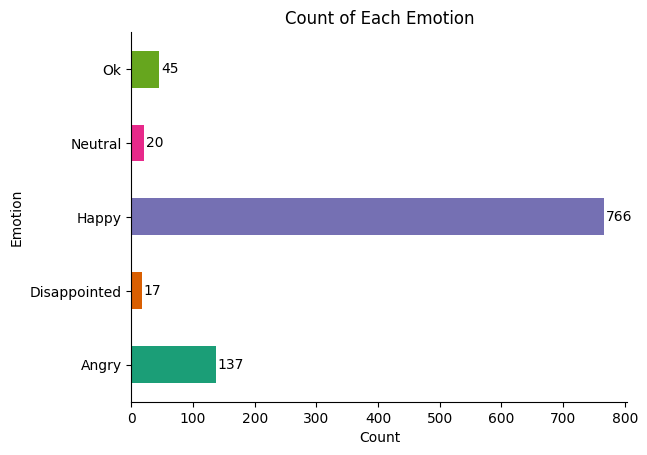

In [ ]:
# Plot the horizontal bar graph
ax = df_merged.groupby('Emotion').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))

# Annotate the bars with their corresponding values
for i, v in enumerate(df_merged.groupby('Emotion').size()):
    ax.text(v + 3, i, str(v), color='black', va='center')

# Hide the right and top spines
ax.spines[['top', 'right']].set_visible(False)

# Set labels and title
plt.xlabel('Count')
plt.ylabel('Emotion')
plt.title('Count of Each Emotion')

# Show the plot
plt.show()

In [ ]:
import folium
from folium.plugins import HeatMap

# 删除 Latitude、Longitude 或 Compound 列为空的行
df_clean = df_merged.dropna(subset=['Latitude', 'Longitude', 'Compound'])

print(f"原始数据：{len(df_merged)} 行")
print(f"清理后：{len(df_clean)} 行")
print(f"删除了：{len(df_merged) - len(df_clean)} 行空数据")

# 创建坐标+得分的列表
location_sentiment = list(zip(df_clean['Latitude'], df_clean['Longitude'], df_clean['Compound']))

# 创建地图
hongkong_map = folium.Map(location=[22.3193, 114.1694], zoom_start=12)

# 创建热力图
heatmap_layer = HeatMap(location_sentiment, radius=15, blur=10, min_opacity=0.5)

# 添加热力图层
hongkong_map.add_child(heatmap_layer)

# 保存地图
hongkong_map.save('/content/drive/MyDrive/hongkong_heatmap.html')

print("✅ 热力图已保存！")

原始数据：985 行
清理后：985 行
删除了：0 行空数据
✅ 热力图已保存！


In [ ]:
import folium
from folium.plugins import HeatMap
import branca.colormap as cm

# 清理数据
df_clean = df_merged.dropna(subset=['Latitude', 'Longitude', 'Compound'])

# 创建地图
hongkong_map = folium.Map(location=[22.3193, 114.1694], zoom_start=12)

# 准备热力图数据
location_sentiment = list(zip(df_clean['Latitude'], df_clean['Longitude'], df_clean['Compound']))

# 添加热力图层
heatmap_layer = HeatMap(location_sentiment, radius=15, blur=10, min_opacity=0.5)
hongkong_map.add_child(heatmap_layer)

# ===== 添加图例 =====
# 创建颜色渐变图例（Compound 得分范围 -1 到 1）
colormap = cm.LinearColormap(
    colors=['blue', 'lightblue', 'green', 'yellow', 'red'],
    vmin=-1, vmax=1,
    caption='情感得分 (Compound Score): 蓝色=负面 → 红色=正面'
)
colormap.add_to(hongkong_map)

# 保存
hongkong_map.save('/content/drive/MyDrive/hongkong_heatmap_with_legend.html')

print("✅ 带图例的热力图已保存！")
print("文件位置：/content/drive/MyDrive/MUDP2020_Social Media/hongkong_heatmap_with_legend.html")

✅ 带图例的热力图已保存！
文件位置：/content/drive/MyDrive/MUDP2020_Social Media/hongkong_heatmap_with_legend.html


In [ ]:
# Create a list of tuples containing latitude, longitude, and sentiment score
location_sentiment = list(zip(df_merged['Latitude'], df_merged['Longitude'], df_merged['Compound']))

# Create a map centered around Hong Kong
hongkong_map = folium.Map(location=[22.3193, 114.1694], zoom_start=15)

# Create a HeatMap layer using the location_sentiment data
heatmap_layer = HeatMap(location_sentiment, radius=25)

# Add the HeatMap layer to the map
hongkong_map.add_child(heatmap_layer)

# Add a legend to the heatmap
hongkong_map.add_child(folium.LayerControl())

# Display the map
hongkong_map.save('/content/drive/MyDrive/hongkong_heatmap_with_legend.html')  # Save the map as an HTML file
hongkong_map


In [ ]:
df_merged.to_excel(folder_path + "Merged_Output.xlsx", index = False)

NameError: name 'folder_path' is not defined

In [ ]:
# 统计情感分布
print(df_merged['Emotion'].value_counts())
print(f"\n平均情感得分：{df_merged['Compound'].mean():.3f}")

Emotion
Happy           766
Angry           137
Ok               45
Neutral          20
Disappointed     17
Name: count, dtype: int64

平均情感得分：0.627


In [ ]:
!pip install python-pptx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.8/472.8 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 13.2 MB/s eta 0:00:00


In [ ]:
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.enum.text import PP_ALIGN

def add_slide(prs, title_text, bullet_points, image_desc="[Insert Image Here]"):
    slide_layout = prs.slide_layouts[1]  # 使用“标题 + 内容”布局
    slide = prs.slides.add_slide(slide_layout)

    # 设置标题
    title = slide.shapes.title
    title.text = title_text

    # 设置正文
    tf = slide.placeholders[1].text_frame
    tf.word_wrap = True
    for point in bullet_points:
        p = tf.add_paragraph()
        p.text = point
        p.level = 0
        p.space_after = Pt(10)

    # 在右侧预留图片说明文字框
    left = Inches(6)
    top = Inches(1.5)
    width = Inches(3)
    height = Inches(5)
    txBox = slide.shapes.add_textbox(left, top, width, height)
    tf_box = txBox.text_frame
    p_box = tf_box.add_paragraph()
    p_box.text = f"📸 Image Placeholder:\n{image_desc}"
    p_box.font.italic = True
    p_box.font.size = Pt(14)

# 创建演示文稿对象
prs = Presentation()

# --- Slide 1: Title Page ---
slide_layout = prs.slide_layouts[0]
slide = prs.slides.add_slide(slide_layout)
title = slide.shapes.title
subtitle = slide.placeholders[1]
title.text = "Social Media Sentiment and Urban Health"
subtitle.text = "A Comparative HIA of Formal vs. Informal Spaces in Sham Shui Po\nCourse: MUDP2020 Values of Urban Design / HIA Assignment"

# --- Slide 2: Research Intent ---
add_slide(prs, "Research Intent: Dual-Site Comparison",
          ["Objective: Assess urban morphology's influence on mental well-being.",
           "Site A (Formal): Trinity Towers - Focus on safety vs. social exclusion.",
           "Site B (Informal): Hop Yik Tai Area - Focus on cohesion vs. hygiene risks.",
           "HIA Goal: Quantifying psychological perception through NLP."],
          "Place your Red-line boundary map here (A vs B labels).")

# --- Slide 3: Methodology - The Tool Advantage ---
add_slide(prs, "Methodology: Octoparse (OTP) Efficiency",
          ["Data Sourcing: Automated extraction via Octoparse.",
           "Scalability: OTP excels in macro-scale analytics (e.g., thousands of URLs).",
           "Efficiency: Significant advantage for city-wide sentiment mapping.",
           "Micro-scale Challenge: Encountered map layer nesting issues for specific POIs."],
          "Screenshot of Octoparse workflow or raw data table.")

# --- Slide 4: Data Refinement - From 6 to 3 ---
add_slide(prs, "Data Preprocessing: Noise Reduction",
          ["The 'Digital Gap': Loss of 3 POIs highlights the digital shadow in informal settings.",
           "Quality over Breadth: Filtered 985 valid reviews for high-fidelity analysis.",
           "Reliability: Sacrificed 3 points to ensure the integrity of the emotional scores.",
           "Final Sample: 985 records processed via BERT-based sentiment model."],
          "Data Funnel Diagram: 6 POIs -> Cleaning -> 3 POIs (985 Reviews).")

# --- Slide 5: Results - 0.627 Sentiment Score ---
add_slide(prs, "Results: The Emotional Landscape",
          ["Overall Sentiment Score: 0.627 (Highly Positive).",
           "Key Finding: SSP maintains high emotional resilience despite physical decay.",
           "Distribution: Significant majority of reviews fall into 'Happy' or 'Ok'.",
           "Conclusion: The study area serves as a vital 'Restorative Space'."],
          "Bar Chart showing the 0.627 score and emotion distribution.")

# --- Slide 6: Site A - Trinity Towers ---
add_slide(prs, "Site A: Trinity Towers (Formal Paradox)",
          ["Drivers: Safety, Modernity, and Environmental Quality.",
           "HIA Risk: Gated nature creates a 'Social Filter'.",
           "Insight: High scores reflect property value, not community connection.",
           "Public Health Impact: Potential risk of Social Isolation."],
          "Photo of Trinity Towers + Word Cloud (Clean, Safe, New).")

# --- Slide 7: Site B - Hop Yik Tai (Informal Healer) ---
add_slide(prs, "Site B: Hop Yik Tai (Informal Healer)",
          ["Drivers: Identity, Affordability, and Human Touch.",
           "HIA Benefit: Functions as a critical 'Third Place'.",
           "Insight: High sentiment confirms role in boosting Social Cohesion.",
           "Public Health Impact: Psychological restoration for low-energy dwellers."],
          "Photo of street crowds + Word Cloud (Vibe, Delicious, Traditional).")

# --- Slide 8: Critical Discussion ---
add_slide(prs, "Discussion: Digital vs. Urban Reality",
          ["Golden Rule: Place attachment is often found in 'messy' data.",
           "Scale Advantage: OTP captures spontaneous voices missed by surveys.",
           "Algorithmic Bias: We must look beyond the 3 'missing' POIs via site walks.",
           "Design Reflection: Data depth is more critical than mere data breadth."],
          "Graphic: 'What the Algorithm Sees' vs. 'What the Resident Feels'.")

# --- Slide 9: Conclusion & Recommendations ---
add_slide(prs, "HIA Recommendations",
          ["1. Protect high-sentiment informal nodes from over-gentrification.",
           "2. Soften gated edges (Trinity Towers) to reconnect with social fabric.",
           "3. A score of 0.627 proves social vitality is a nutrient for health.",
           "Future: Balancing privacy with social permeability."],
          "Design sketch showing a permeable street edge.")

# 保存文件
prs.save('Sham_Shui_Po_HIA_Report.pptx')
print("Successfully generated: Sham_Shui_Po_HIA_Report.pptx")

Successfully generated: Sham_Shui_Po_HIA_Report.pptx


\